# Ridgeline Coffee Co. Supply Chain Assistant

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Shacxify/BUS4118S-AgenticAIinMarketing/blob/main/supplychain/supplychain_demo.ipynb)

A multi-agent supply chain assistant built with **LangGraph** and **Google Gemini**. "Atlas" helps the
operations team at Ridgeline Coffee Co. (the same fictional roaster as our ad agent and customer service
chatbot) keep green coffee and packaging in stock. This notebook shows:

1. **System prompt** that defines the assistant's role (Atlas, the supply chain analyst)
2. **Three supply chain request types handled by different agents:** Inventory & Demand, Logistics, Procurement
3. **Conversation memory** across turns with LangGraph `MemorySaver`

**To run in Colab:** click the 🔑 *Secrets* icon in the left sidebar, add a secret named `GEMINI_API_KEY`
with your [Google AI Studio](https://aistudio.google.com/apikey) key, and turn on *Notebook access*.
Then choose *Runtime → Run all*.

## 1. Setup

In Colab this clones the repository and installs LangGraph and the Gemini integration. Locally it uses the existing checkout.

In [1]:
import os, sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not os.path.exists("BUS4118S-AgenticAIinMarketing"):
        !git clone -q --branch main https://github.com/Shacxify/BUS4118S-AgenticAIinMarketing.git
    %cd BUS4118S-AgenticAIinMarketing
    !pip install -q "langgraph>=1.0" "langchain-google-genai>=4.0" python-dotenv
elif os.path.basename(os.getcwd()) == "supplychain":
    os.chdir("..")   # work from the repo root
sys.path.insert(0, os.getcwd())
print("Running in", "Google Colab" if IN_COLAB else "a local checkout")

Running in a local checkout


## 2. Gemini API key

Read from Colab Secrets (or a hidden prompt) in Colab, and from `.env` locally. The key is never printed or saved in the notebook.

In [2]:
if IN_COLAB:
    from google.colab import userdata
    try:
        os.environ["GEMINI_API_KEY"] = userdata.get("GEMINI_API_KEY")
    except Exception:
        from getpass import getpass
        os.environ["GEMINI_API_KEY"] = getpass("Gemini API key: ")
print("Gemini key loaded:", bool(os.getenv("GEMINI_API_KEY")) or os.path.exists(".env"))

Gemini key loaded: True


## 3. The system prompt

Every agent shares this operations persona. Each specialist adds its own role prompt on top (see `supplychain/prompts.py`).

In [3]:
from supplychain.prompts import OPS_SYSTEM_PROMPT
print(OPS_SYSTEM_PROMPT)

You are Atlas, the supply chain assistant for Ridgeline Coffee Co., a small direct-to-consumer
specialty coffee roaster. You help the operations team keep green coffee and packaging in stock, track
inbound shipments, and buy from the right supplier. Today's date is October 26, 2026.

Rules:
- Use your tools for facts. Never invent stock levels, ETAs, prices, suppliers, or PO numbers.
  Quote PO numbers, quantities and units exactly as your tools return them.
- Reuse items and PO numbers mentioned earlier in the conversation instead of asking again.
- Never place an order unless the user has clearly approved that exact supplier and quantity.
- Lead with the answer and the business impact (will we run out, when, what it costs). Then one
  recommended next step.
- Tone: clear, direct, like a sharp operations analyst. Plain text, no markdown headings or tables.
  Usually under 130 words.
- If something is outside what you can do, say so and suggest who on the team should handle it.


## 4. The supply chain data

Mock data in `supplychain/data.py`: six inventory items, approved suppliers, and four inbound purchase orders. "Today" is fixed at Oct 26, 2026 so results are reproducible. Brazil Cerrado, the base of the house blend, is the item to watch.

In [4]:
from supplychain.tools import inventory_status
from supplychain.data import INVENTORY

print(f"{'item':<9}{'name':<30}{'on hand':>9}{'use/day':>9}{'days cover':>12}  status")
for item in INVENTORY:
    s = inventory_status(item)
    print(f"{item:<9}{s['name']:<30}{s['on_hand']:>9,}{s['daily_usage']:>9}{s['days_of_cover']:>12}  {s['status']}")

item     name                            on hand  use/day  days cover  status
GC-BRZ   Brazil Cerrado (green)              600       70         8.6  low: below reorder point
GC-COL   Colombia Huila (green)            2,100       45        46.7  healthy
GC-ETH   Ethiopia Yirgacheffe (green)        420       30        14.0  low: below reorder point
GC-SUM   Sumatra Mandheling (green)          900       20        45.0  healthy
GC-DEC   Swiss Water Decaf (green)           480       12        40.0  healthy
PK-12OZ  12 oz valve bags                  5,200      480        10.8  healthy


## 5. Build the multi-agent graph

A **router** classifies each message and hands it to one specialist. Specialists loop with their own tools until they can answer. The graph is compiled with a `MemorySaver` checkpointer.

inventory     tools: check_inventory, forecast_stockout
logistics     tools: track_shipment, list_inbound_shipments
procurement   tools: compare_suppliers, create_purchase_order
general       tools: none


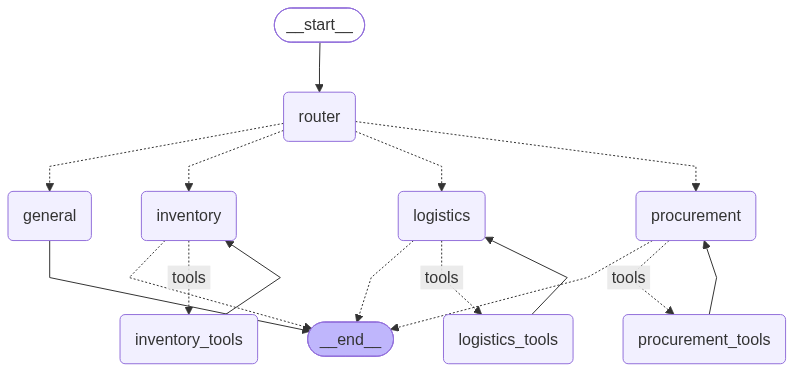

In [5]:
from IPython.display import Image, display
from supplychain.graph import AGENTS, build_graph

graph = build_graph()
for name, (_, tools) in AGENTS.items():
    print(f"{name:<13} tools: {', '.join(t.name for t in tools) or 'none'}")
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:   # the PNG is rendered by an online service; fall back to the Mermaid source
    print(graph.get_graph().draw_mermaid())

## 6. A five-turn conversation across all three agents

Each turn shows which agent handled it, which tools it called, and how many messages `MemorySaver` has stored for this conversation (`thread_id`). Later turns say "that shipment" and "the fastest option"; the agents resolve them from memory.

In [6]:
import time
from chatbot.chat import ask

def turn(thread_id, text):
    reply, route, tools = ask(graph, thread_id, text)
    saved = len(graph.get_state({"configurable": {"thread_id": thread_id}}).values["messages"])
    print(f"Ops manager: {text}\n")
    print(f"[{route} agent | tools: {', '.join(tools) or 'none'} | {saved} messages in memory]\n")
    print(f"Atlas: {reply}")
    time.sleep(20)   # a turn can make 4-5 Gemini calls; the free tier allows 15 per minute

**Turn 1: inventory.** The inventory agent checks stock and projects a stockout, counting inbound shipments and holiday demand.

In [7]:
turn("ops-morning", "Morning Atlas. How are we looking on Brazil Cerrado green coffee? Are we going to run out?")

Ops manager: Morning Atlas. How are we looking on Brazil Cerrado green coffee? Are we going to run out?

[inventory agent | tools: check_inventory, forecast_stockout | 6 messages in memory]

Atlas: Brazil Cerrado green coffee is at 600 lb, which is below our 840 lb reorder point with only 8.6 days of cover left. We will stock out on November 3, resulting in 6 days short and roughly 380 lb of unmet demand before PO-2211 (1,500 lb, currently delayed) arrives on November 9. This threatens our House Blend and Night Shift Espresso production right as holiday demand begins.

Recommended next step: Expedite PO-2211 with the supplier to pull the November 9 ETA forward by at least six days.


**Turn 2: logistics.** "That Brazil shipment" is never named; the logistics agent gets PO-2211 from turn 1 and tracks it.

In [8]:
turn("ops-morning", "That Brazil shipment, is it still on schedule? What's going on with it?")

Ops manager: That Brazil shipment, is it still on schedule? What's going on with it?

[logistics agent | tools: track_shipment | 10 messages in memory]

Atlas: PO-2211 (1,500 lb of Brazil Cerrado green) is currently delayed by 7 days via MSC ocean freight due to port congestion at Santos and a late vessel departure. The new ETA is November 9, missing our original November 2 target. Because we stock out on November 3, this delay leaves us short for 6 days (roughly 380 lb of unmet demand). 

Recommended next step: Check with Fazenda Alta Exports to see if air freight or a smaller bridge order is possible to cover the November 3 through November 8 gap.


**Turn 3: procurement.** The procurement agent compares suppliers against the stockout date and shortfall found earlier.

In [9]:
turn("ops-morning", "We can't miss house blend orders. Who can get us enough Brazil to bridge the gap, "
                    "and what will it cost?")

Ops manager: We can't miss house blend orders. Who can get us enough Brazil to bridge the gap, and what will it cost?

[procurement agent | tools: compare_suppliers | 14 messages in memory]

Atlas: Bay Area Green Coffee can deliver 380 lb by October 29 (arriving in time to prevent our November 3 stockout) for $1,558 total ($4.10/lb). Pacific Bean Traders is slightly cheaper at $1,463 ($3.85/lb), arriving November 1. 

Recommended next step: Approve an order with Bay Area Green Coffee for 380 lb to guarantee arrival before we run out.


**Turn 4: procurement action.** The manager approves, so the agent calls `create_purchase_order`.

In [10]:
turn("ops-morning", "Go with the fastest option. Place an order for 500 lb.")

Ops manager: Go with the fastest option. Place an order for 500 lb.

[procurement agent | tools: create_purchase_order | 18 messages in memory]

Atlas: PO-2231 has been placed with Bay Area Green Coffee for 500 lb of Brazil Cerrado (green) at $2,050 total ($4.10 per lb), arriving on October 29. This completely prevents our November 3 stockout and protects House Blend production ahead of the holidays.

Recommended next step: Monitor the inbound tracking for PO-2231 to ensure it arrives by the October 29 target.


**Turn 5: memory check.** No tools: the answer comes from the conversation `MemorySaver` kept.

In [11]:
turn("ops-morning", "Quick recap for my notes: the new PO number, when it lands, and when the delayed "
                    "shipment arrives.")

Ops manager: Quick recap for my notes: the new PO number, when it lands, and when the delayed shipment arrives.

[general agent | tools: none | 20 messages in memory]

Atlas: PO-2231 is secured for 500 lb of Brazil Cerrado (green) from Bay Area Green Coffee, landing on October 29 to prevent our November 3 stockout. Meanwhile, the delayed shipment, PO-2211 (1,500 lb), is now scheduled to arrive on November 9. This fully covers our gap and protects holiday production.

Recommended next step: Confirm receipt of PO-2231's order confirmation for your records.


## 7. What `MemorySaver` stored

The checkpoint for this thread holds every message: manager turns, tool calls, tool results and replies.

In [12]:
state = graph.get_state({"configurable": {"thread_id": "ops-morning"}})
for i, m in enumerate(state.values["messages"], 1):
    kind = type(m).__name__.replace("Message", "")
    calls = ", ".join(c["name"] for c in getattr(m, "tool_calls", None) or [])
    text = (f"calls {calls}" if calls else m.text).replace("\n", " ")
    print(f"{i:>2}. {kind:<6} {text[:95]}")

 1. Human  Morning Atlas. How are we looking on Brazil Cerrado green coffee? Are we going to run out?
 2. AI     calls check_inventory
 3. Tool   {"found": true, "item_code": "GC-BRZ", "name": "Brazil Cerrado (green)", "unit": "lb", "on_hand
 4. AI     calls forecast_stockout
 5. Tool   {"item_code": "GC-BRZ", "name": "Brazil Cerrado (green)", "unit": "lb", "horizon_days": 30, "ho
 6. AI     Brazil Cerrado green coffee is at 600 lb, which is below our 840 lb reorder point with only 8.6
 7. Human  That Brazil shipment, is it still on schedule? What's going on with it?
 8. AI     calls track_shipment
 9. Tool   {"found": true, "po_number": "PO-2211", "item": "GC-BRZ", "qty": 1500, "supplier": "Fazenda Alt
10. AI     PO-2211 (1,500 lb of Brazil Cerrado green) is currently delayed by 7 days via MSC ocean freight
11. Human  We can't miss house blend orders. Who can get us enough Brazil to bridge the gap, and what will
12. AI     calls compare_suppliers
13. Tool   {"item_code": "GC-BRZ", "na

## 8. The bridge order fixes the stockout

Re-running the forecast now counts the new PO.

In [13]:
from supplychain.tools import project_stock
print(project_stock("GC-BRZ")["verdict"])

no stockout in horizon


## 9. Memory is per conversation

A new `thread_id` starts empty, so Atlas doesn't know which PO "my PO" means. It can still see the purchasing system (including the new order), but not what was said in the other conversation.

In [14]:
turn("new-shift", "When does my PO arrive?")

Ops manager: When does my PO arrive?

[logistics agent | tools: list_inbound_shipments | 4 messages in memory]

Atlas: You have four open purchase orders inbound: PO-2207 (1,000 lb Ethiopia Yirgacheffe) arrives November 6; PO-2211 (1,500 lb Brazil Cerrado via MSC ocean) is delayed 7 days due to Santos port congestion and now arrives November 9; PO-2216 (10,000 units 12 oz valve bags) arrives November 2; and PO-2231 (500 lb Brazil Cerrado from Oakland) arrives October 29. 

The 7-day delay on PO-2211 pushes back our main Brazil restock, but the domestic bridge order (PO-2231) arriving October 29 should cover our needs in the interim. 

Would you like me to track PO-2211 in detail to monitor any further updates?


## 10. Try it yourself

In Colab this starts an interactive chat (type `quit` to stop). Try Brazil, Colombia, Ethiopia, Sumatra, decaf or bags, and POs PO-2207, PO-2211 or PO-2216. Locally, run `python -m supplychain.chat` instead.

In [15]:
if IN_COLAB:
    while (text := input("You: ").strip()).lower() not in ("quit", "exit", ""):
        turn("colab-session", text)
        print()
else:
    print("Interactive chat runs in Colab. Locally: python -m supplychain.chat")

Interactive chat runs in Colab. Locally: python -m supplychain.chat
